# [RQ_2 · HỖ TRỢ] Thí nghiệm MLP — Config C của Vũ

Dùng bộ tham số MLP của Phúc với **Config C gồm 30 cột** của Vũ. Đối chiếu thêm với **A + lịch sử** của V1 trên cùng các giờ đủ lịch sử.

Đọc `train.csv` và `validation.csv` trong `data/processed`. Để dựng đúng cột C, tạo các đặc trưng thời gian theo `src.features` và ánh xạ 11 cột `weather_main_*` sang `weather_*`. Config C giữ `is_holiday` và sử dụng đúng bộ cột đã khai báo trong `src.features.CONFIG_C`.

Phương án C dùng cách tiền xử lý MLP của Vũ, gồm điền thiếu bằng trung vị và chuẩn hóa toàn bộ đầu vào. A + lịch sử giữ pipeline của V1. Cả hai chuẩn hóa mục tiêu trong lúc fit. So sánh hai phương án phản ánh khác biệt về cả đặc trưng và tiền xử lý đầu vào.

Thí nghiệm dự đoán từng giờ, với thời tiết cùng giờ và lưu lượng thực tế ở các giờ trước có sẵn.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## Params

In [1]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "batch_size": 256,
        "max_iter": 500,
        "early_stopping": False,
        "random_state": 42,
    },
}

CV_SPLITS = 3
CALENDAR_COLUMNS = ["hour", "day_of_week", "month"]
BINARY_COLUMNS = ["is_weekend", "is_holiday"]
TARGET_COLUMN = "traffic_volume"
CLIP_NEGATIVE_PREDICTIONS = True
HOURS_TO_PLOT = 72

## Đọc dữ liệu và chuẩn bị đặc trưng Config C

In [2]:
from datetime import datetime
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cwd = Path.cwd()
project_dir = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "metro_interstate_traffic_volume")
        if (candidate / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train.csv.")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.features import (
    CONFIG_C, HISTORY_FEATURES, WEATHER_GROUP_FEATURES, add_history_features, add_time_features,
)
from src.models import make_model

processed_dir = project_dir / "data" / "processed"
import sys
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=project_dir)
train, validation = data_splits["train"], data_splits["validation"]

assert train.columns.equals(validation.columns)
for part in (train, validation):
    assert part["date_time"].is_unique
    assert part["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

holiday_columns = [column for column in train.columns if column.startswith("holiday_")]
binary_columns = BINARY_COLUMNS + holiday_columns
features_A = CALENDAR_COLUMNS + binary_columns

weather_column_map = {
    column.replace("weather_", "weather_main_", 1): column
    for column in WEATHER_GROUP_FEATURES
}
combined = pd.concat([train, validation], ignore_index=True).rename(columns=weather_column_map)
history_table = add_history_features(add_time_features(combined))
train = history_table.iloc[:len(train)].copy()
validation = history_table.iloc[len(train):].copy()

CONFIG_FEATURES = {
    "A + lịch sử": [*features_A, *HISTORY_FEATURES],
    "Config C": list(CONFIG_C),
}

assert len(CONFIG_FEATURES["Config C"]) == 30
assert set(CONFIG_C) <= set(history_table.columns)

display(pd.DataFrame([
    {
        "Tập": name,
        "Tổng số giờ": len(part),
        "Số giờ đủ lịch sử": part[HISTORY_FEATURES].notna().all(axis=1).sum(),
    }
    for name, part in (("Train", train), ("Validation", validation))
]))

,Tập,Tổng số giờ,Số giờ đủ lịch sử
0,Train,28402,22503
1,Validation,6086,6050


## So sánh trên 3 fold theo thời gian

Tạo ranh giới các fold trên train theo cách V1 ngày 18/11 dùng. Sau đó giữ những giờ đủ lịch sử trong phần học và phần chấm của mỗi fold, dùng cùng các dòng cho hai mô hình. Tổng cộng có 6 lần fit trong CV.

In [3]:
def fit_mlp(frame, config):
    columns = CONFIG_FEATURES[config]
    if config == "Config C":
        params = {f"model__regressor__{key}": value for key, value in MODEL_PARAMS["MLP"].items()}
        pipeline = make_model("MLP", columns).set_params(**params)
        return pipeline.fit(frame[columns], frame[TARGET_COLUMN])

    transformers = [
        ("calendar", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CALENDAR_COLUMNS),
        ("binary", "passthrough", binary_columns),
    ]
    transformers.append(("history", StandardScaler(), HISTORY_FEATURES))

    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer(transformers)),
        ("model", TransformedTargetRegressor(
            regressor=MLPRegressor(**MODEL_PARAMS["MLP"]),
            transformer=StandardScaler(),
        )),
    ])
    return pipeline.fit(frame[columns], frame[TARGET_COLUMN])


def predict_volume(model, frame, config):
    prediction = model.predict(frame[CONFIG_FEATURES[config]])
    if CLIP_NEGATIVE_PREDICTIONS:
        prediction = prediction.clip(min=0)
    return prediction


def keep_history(frame):
    return frame.dropna(subset=HISTORY_FEATURES)


cv_rows = []
for fold, (train_idx, score_idx) in enumerate(TimeSeriesSplit(n_splits=CV_SPLITS).split(train), start=1):
    fit = keep_history(train.iloc[train_idx])
    score = keep_history(train.iloc[score_idx])
    for config in CONFIG_FEATURES:
        print(f"Fold {fold}/{CV_SPLITS} · {config}", flush=True)
        model = fit_mlp(fit, config)
        prediction = predict_volume(model, score, config)
        cv_rows.append({
            "Cấu hình": config,
            "Fold": fold,
            "Giờ train": len(fit),
            "Giờ chấm": len(score),
            "Train đến": fit["date_time"].max(),
            "Chấm từ": score["date_time"].min(),
            "Chấm đến": score["date_time"].max(),
            "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        })

cv_table = pd.DataFrame(cv_rows)
cv_summary = cv_table.groupby("Cấu hình", sort=False)["MAE"].mean().rename("MAE CV").reset_index()
display(cv_table.round(3))
display(cv_summary.round(3))

Fold 1/3 · A + lịch sử
Fold 1/3 · Config C
Fold 2/3 · A + lịch sử
Fold 2/3 · Config C
Fold 3/3 · A + lịch sử
Fold 3/3 · Config C


,Cấu hình,Fold,Giờ train,Giờ chấm,Train đến,Chấm từ,Chấm đến,MAE
0,A + lịch sử,1,5841,5302,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,247.266
1,Config C,1,5841,5302,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,302.520
2,A + lịch sử,2,11143,4441,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,245.850
3,Config C,2,11143,4441,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,268.189
4,A + lịch sử,3,15584,6919,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,254.676
5,Config C,3,15584,6919,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,278.111


,Cấu hình,MAE CV
0,A + lịch sử,249.264
1,Config C,282.940


## Đánh giá trên validation và lưu Excel

Fit lại cả hai mô hình trên cùng tập train đủ lịch sử. Chấm cả hai trên cùng các giờ validation đủ lịch sử. Mỗi lần chạy tạo một file Excel, ghi tham số, MAE, RMSE, R² và điểm từng fold.

In [4]:
fit = keep_history(train)
score = keep_history(validation)
prediction_table = score[["date_time", TARGET_COLUMN]].copy()
rows = []
for config in CONFIG_FEATURES:
    print(f"Validation · {config}", flush=True)
    model = fit_mlp(fit, config)
    prediction = predict_volume(model, score, config)
    prediction_table[config] = prediction
    rows.append({
        "Cấu hình": config,
        "Số đặc trưng": len(CONFIG_FEATURES[config]),
        "Giờ train": len(fit),
        "Giờ validation": len(score),
        "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        "RMSE": mean_squared_error(score[TARGET_COLUMN], prediction) ** 0.5,
        "R2": r2_score(score[TARGET_COLUMN], prediction),
        "n_iter": model.named_steps["model"].regressor_.n_iter_,
    })

params = {**MODEL_PARAMS["MLP"], "hidden_layer_sizes": str(MODEL_PARAMS["MLP"]["hidden_layer_sizes"])}
results = pd.DataFrame(rows).merge(cv_summary, on="Cấu hình", validate="one_to_one").assign(**params)
baseline_mae = results.loc[results["Cấu hình"].eq("A + lịch sử"), "MAE"].iloc[0]
results["Chênh MAE so với A + lịch sử"] = results["MAE"] - baseline_mae
display(results.round({"MAE": 3, "RMSE": 3, "R2": 4, "MAE CV": 3}))

run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S_%f")
experiment_dir = project_dir / "experiments" / "18-11-2026_ConfigA_HistoryMLP_Phuc"
excel_path = experiment_dir / f"ConfigC_MLP_V4_{run_id}.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Kết quả", index=False)
    cv_table.to_excel(writer, sheet_name="CV từng fold", index=False)
print(f"Đã lưu Excel tại {excel_path}")

Validation · A + lịch sử
Validation · Config C


,Cấu hình,Số đặc trưng,Giờ train,Giờ validation,MAE,RMSE,R2,n_iter,MAE CV,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,batch_size,max_iter,early_stopping,random_state,Chênh MAE so với A + lịch sử
0,A + lịch sử,20,22503,6050,194.780,302.769,0.9762,57,249.264,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,0.000000
1,Config C,30,22503,6050,234.768,357.203,0.9669,86,282.940,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,39.987136


Đã lưu Excel tại d:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\18-11-2026_ConfigA_HistoryMLP_Phuc\ConfigC_MLP_V4_20261118_102041_215507.xlsx


## Vẽ và lưu biểu đồ dự đoán

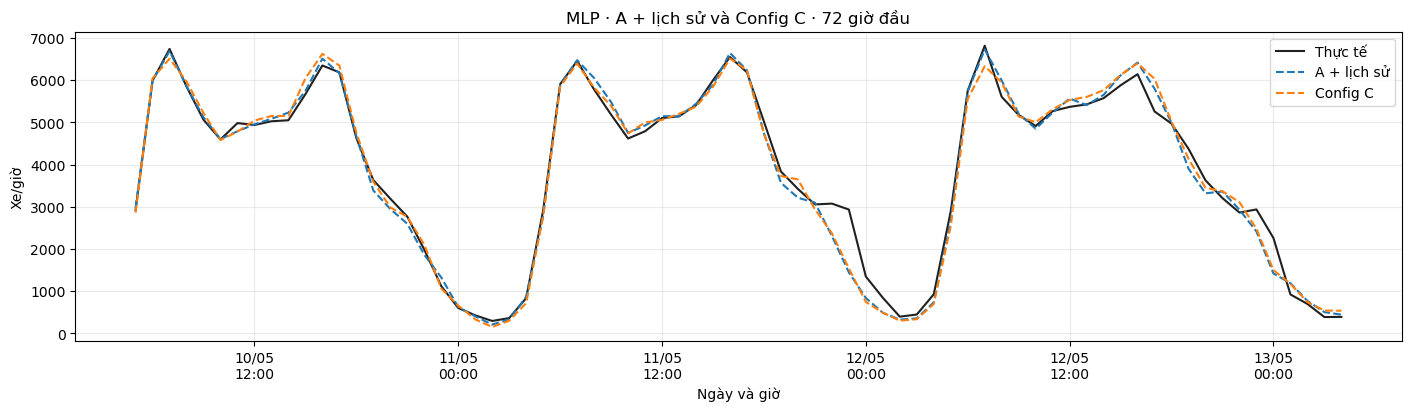

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)
# Giữ NaN ở các giờ thiếu để biểu đồ ngắt tại khoảng trống.
plot_data = prediction_table.set_index("date_time").reindex(plot_index)

fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
ax.plot(plot_data.index, plot_data[TARGET_COLUMN], color="#202020", label="Thực tế")
for config in CONFIG_FEATURES:
    ax.plot(plot_data.index, plot_data[config], linestyle="--", label=config)
ax.set_title("MLP · A + lịch sử và Config C · 72 giờ đầu")
ax.set_ylabel("Xe/giờ")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.set_xlabel("Ngày và giờ")

output_dir = experiment_dir / "img"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"config_c_mlp_v4_{HOURS_TO_PLOT}h_{run_id}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

## Nhận xét sau khi chạy

- So MAE từng fold, MAE CV trung bình và các chỉ số validation giữa A + lịch sử và Config C.
- Khi đối chiếu MLP Config C của Vũ, ghi rõ tham số, nguồn dữ liệu và cách chia fold đã dùng. Mốc validation của Vũ là MAE **227,20** và RMSE **349,31 xe/giờ**.

<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_2

**Vai trò: HỖ TRỢ.** Mã đối chiếu: [E30](../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). 

- **Câu hỏi:** Cùng tham số MLP, chuyển cả feature và preprocessing sang nhánh C30 có tốt hơn không?
- **Đánh giá:** Hỗ trợ chọn pipeline có history: giữ tham số MLP nhưng chuyển A+H20 sang C30 và preprocessing của Vũ làm MAE 194,780→234,768, RMSE 302,769→357,203. Pipeline hiện có A+H tốt hơn trong phép so sánh này.
- **Giới hạn kết luận:** Đã thay cả feature và preprocessing, nên không dùng để kết luận riêng weather gây tăng lỗi. Không đồng nhất kết quả MLP này với run MLP C30 của Vũ có tham số khác.
- **Bằng chứng:** [E30: ConfigC_MLP_V4_20261118_102041_215507.xlsx](ConfigC_MLP_V4_20261118_102041_215507.xlsx).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
